# Example on realistic data AVRAMI
Example on realistic sampled data (just 3 points + initial conditions). We solved the scaling issue by adapting a paper of 2024. 
Ea and A are output at every timestep t, so they are dependent on the time step.

In [470]:
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import functools

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ScaledSigmoid(nn.Module):
    def __init__(self, min_val, max_val):
        super(ScaledSigmoid, self).__init__()
        self.min_val = min_val
        self.max_val = max_val

    def forward(self, x):
        # Apply sigmoid to squish the output to (0, 1)
        x = torch.sigmoid(x)
        # Scale and shift to the desired range [min_val, max_val]
        return self.min_val + x * (self.max_val - self.min_val)

class EquationValue(nn.Module):
    def __init__(self, input_dims, min_val, max_val):
        super().__init__()
        assert min_val < max_val, "min_val must be less than max_val"
        self.min_val = min_val
        self.max_val = max_val
        self.scaled_sigmoid = ScaledSigmoid(min_val, max_val)
        self.input_dims = input_dims
        self.linear = nn.Linear(input_dims, 1)     

        # # Target a pre-activation range of approximately [-4, 4].
        # # If we assume inputs are roughly unit variance, then scale the weights:
        # weight_range = self.max_val / math.sqrt(input_dims)  # This is a heuristic value.
        # nn.init.uniform_(self.linear.weight, -weight_range, weight_range)
        
        # # Similarly, initialize biases to cover a wide range.
        # # Here we set biases uniformly over [-4,4].
        # nn.init.uniform_(self.linear.bias, self.min_val, self.max_val)  

    def forward(self, x):
        # Apply the linear layer
        x = self.linear(x)
        # Apply the scaled sigmoid activation function
        x = self.scaled_sigmoid(x)
        return x

class DiscoveryNet(nn.Module):
    def __init__(self, input_dim, output_dim, n_units=100, epochs=1000, loss = nn.MSELoss(), lr=1e-3, loss2=None, loss2_weight=0.1, patience=0) -> None:
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.epochs = epochs
        self.loss = loss
        self.loss2 = loss2
        self.loss2_weight = loss2_weight
        self.lr = lr 
        self.n_units = n_units
        self.patience = patience
    
        self.layers = nn.Sequential(
            nn.Linear(input_dim, self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
        )
        # self.out = nn.Linear(self.n_units, output_dim)

        self.d = EquationValue(self.n_units, 0, 1)
        self.Ea = EquationValue(self.n_units, 30000, 70000)
        self.A = EquationValue(self.n_units, 1e-5, 1e-1)  # 0.00001 to 0.1
    
    def forward(self, x):
        h = self.layers(x)

        d = self.d(h)
        Ea = self.Ea(h)
        A = self.A(h)
        out = torch.cat((d, Ea, A), dim=1)

        return out

    def fit(self, X, y, scaler=None):
        Xt = np_to_tensor(X)
        yt = np_to_tensor(y)

        optimiser = optim.Adam(self.parameters(), lr=self.lr)
        self.train()
        losses = []
        data_losses = []
        physic_losses = []
        for ep in range(self.epochs):
            optimiser.zero_grad()
            outputs = self.forward(Xt)

            d = outputs[:, 0].reshape(-1, 1)
            # d = scaler.inverse_transform(d).type(torch.float32) if scaler else d

            data_loss = self.loss(yt, d)
            if self.loss2:
                physic_loss = self.loss2_weight * self.loss2(self)
                loss = data_loss + physic_loss
                physic_losses.append(physic_loss.item())
            else:
                loss = data_loss
            data_losses.append(data_loss.item())

            loss.backward()
            optimiser.step()
            losses.append(loss.item())
            if ep % int(self.epochs / 10) == 0:
                if physic_losses:
                    physic_loss_avg = np.mean(physic_losses).item()
                    print("Estimated Ea :", outputs[:, 1].reshape(-1, 1).mean().item())
                    print("Estimated A :", outputs[:, 2].reshape(-1, 1).mean().item())
                else:
                    physic_loss_avg = 0

                print(f"Epoch {ep}/{self.epochs}, loss: {np.mean(losses).item():.6f} - data_loss: {np.mean(data_losses).item():.6f} - physic_loss: {physic_loss_avg:.6f}")
        return losses

    def predict(self, X):
        self.eval()
        out = self.forward(np_to_tensor(X))
        return out.detach().cpu().numpy()

def np_to_tensor(x):
    if isinstance(x, torch.Tensor) and x.device == DEVICE:
        return x
    elif isinstance(x, torch.Tensor):
        return x.to(DEVICE)
    elif isinstance(x, list):
        x = np.array(x)
    
    n_samples = len(x)
    return torch.from_numpy(x).to(torch.float).to(DEVICE).reshape(n_samples, -1)

In [465]:
# testing equationValue

etest = [EquationValue(10, 0, 1), EquationValue(10, 20000, 100000), EquationValue(10, 1e-5, 1e-1)]
x = torch.randn(10, 10)
print(x.min(), x.max())
# x = torch.randn(10, 10) ** 10
# print(x.min(), x.max())
for e in etest:
    out = e(x)
    print(out.min(), out.max())


tensor(-2.7679) tensor(2.4445)
tensor(0.3919, grad_fn=<MinBackward1>) tensor(0.6946, grad_fn=<MaxBackward1>)
tensor(35612.0156, grad_fn=<MinBackward1>) tensor(77539.6094, grad_fn=<MaxBackward1>)
tensor(0.0196, grad_fn=<MinBackward1>) tensor(0.0772, grad_fn=<MaxBackward1>)


In [381]:
class TorchMinMaxScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.min_val = torch.tensor(0, dtype=torch.float32, device=DEVICE)
        self.max_val = torch.tensor(1, dtype=torch.float32, device=DEVICE)

    def fit_transform(self, data):
        # Compute min and max values from the data
        if not isinstance(data, torch.Tensor):
            data = torch.from_numpy(data)
        self.min_val = torch.min(data, dim=0)[0].to(device=DEVICE)
        self.max_val = torch.max(data, dim=0)[0].to(device=DEVICE)
        return self.transform(data)
    
    def transform(self, x):
        prev = None
        if not isinstance(x, torch.Tensor):
            x = torch.from_numpy(x).to(device=DEVICE)
        if x.device != DEVICE:
            prev  = x.device
            x = x.to(device=DEVICE)
        # Scale x to the range [0, 1]
        scaled = (x - self.min_val) / (self.max_val - self.min_val)
        if prev != DEVICE:
            scaled = scaled.to(device=prev)
        return scaled.type(torch.float32)
    
    def inverse_transform(self, x_scaled):
        # Inverse scaling: bring x_scaled back to original range
        return x_scaled * (self.max_val - self.min_val) + self.min_val

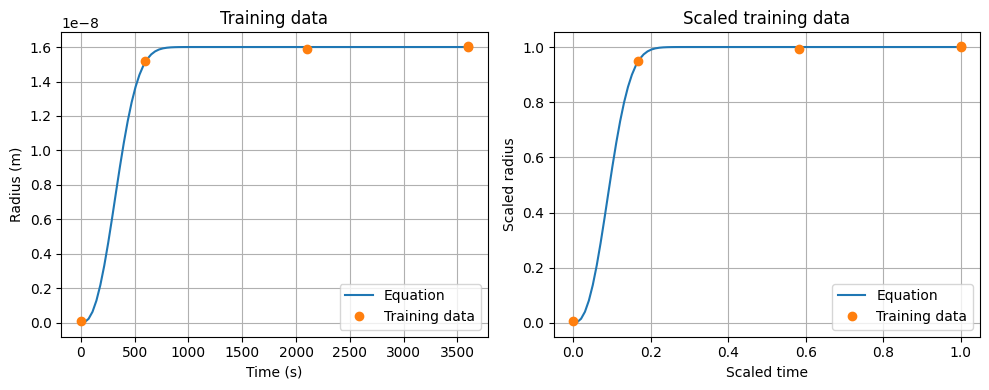

In [382]:
import numpy as np
import functools
import matplotlib.pyplot as plt

def avrami_law(t,Ea,R,T,A,n,r_max):
    K = A * np.exp(-Ea / (R * T))
    d = r_max * (1 - np.exp(-K * t**n))

    return d

np.random.seed(10)
A = 0.0015              # Increased to speed up transformation
Ea = 35000            # Lowered to increase reaction rate
T = 500               # Higher temp for faster growth
r_max = 16e-9         # Max radius in meters (30 nm)
n = 2.5
R = 8.314

TIME_MAX = 3600  # seconds

# Time array
gt_times_X = np.linspace(0, TIME_MAX, 100)
eq = functools.partial(avrami_law, Ea=Ea, A=A, T=T, r_max=r_max, n=n, R=R)
gt_d_Y = eq(gt_times_X) # * 1e9

# Training data with noise
N_POINTS = 3

train_times_X = np.asarray([0])  # Add the initial condition
train_times_X = np.append(train_times_X, np.linspace(600, TIME_MAX, N_POINTS))
train_times_X = np.append(train_times_X, TIME_MAX)  # Add the final condition

noise_std = 0.005 * r_max
train_d_Y = (eq(train_times_X) + noise_std * np.random.randn(len(train_times_X))) # * 1e9

# Scale data
scaler_X = TorchMinMaxScaler()
scaler_Y = TorchMinMaxScaler()

# Fit and transform the training data
eq_times_X_scaled = scaler_X.fit_transform(gt_times_X.reshape(-1, 1)).type(torch.float32)
eq_d_Y_scaled = scaler_Y.fit_transform(gt_d_Y.reshape(-1, 1)).type(torch.float32)

# Transform test data using the already fitted scalers
train_times_X_scaled = scaler_X.transform(train_times_X.reshape(-1, 1)).type(torch.float32)
train_d_Y_scaled = scaler_Y.transform(train_d_Y.reshape(-1, 1)).type(torch.float32)


# Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(train_times_X, train_d_Y , 'o', label="Training data")
# noisy data
plt.grid()
plt.legend()
plt.title("Training data")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.subplot(1, 2, 2)
plt.plot(eq_times_X_scaled, eq_d_Y_scaled, label="Equation")
plt.plot(train_times_X_scaled.cpu().numpy(), train_d_Y_scaled.cpu().numpy() , 'o', label="Training data")
plt.grid()
plt.legend()
plt.title("Scaled training data")
plt.xlabel("Scaled time")
plt.ylabel("Scaled radius")
plt.tight_layout()
plt.show(block=False)

Epoch 0/30000, loss: 0.248734 - data_loss: 0.248734 - physic_loss: 0.000000
Epoch 3000/30000, loss: 0.012987 - data_loss: 0.012987 - physic_loss: 0.000000
Epoch 6000/30000, loss: 0.006496 - data_loss: 0.006496 - physic_loss: 0.000000
Epoch 9000/30000, loss: 0.004332 - data_loss: 0.004332 - physic_loss: 0.000000
Epoch 12000/30000, loss: 0.003250 - data_loss: 0.003250 - physic_loss: 0.000000
Epoch 15000/30000, loss: 0.002600 - data_loss: 0.002600 - physic_loss: 0.000000
Epoch 18000/30000, loss: 0.002167 - data_loss: 0.002167 - physic_loss: 0.000000
Epoch 21000/30000, loss: 0.001858 - data_loss: 0.001858 - physic_loss: 0.000000
Epoch 24000/30000, loss: 0.001626 - data_loss: 0.001626 - physic_loss: 0.000000
Epoch 27000/30000, loss: 0.001445 - data_loss: 0.001445 - physic_loss: 0.000000


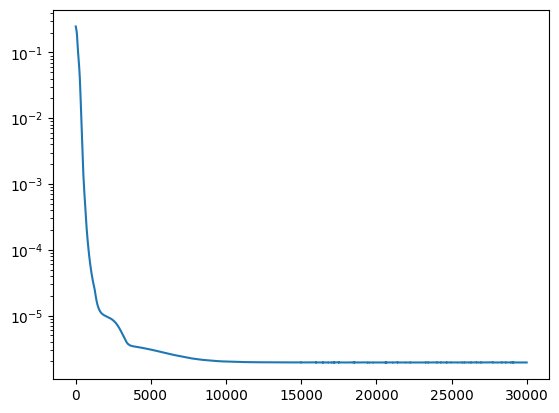

In [383]:

vanilla = DiscoveryNet(1, 3, loss2=None, loss2_weight=1, epochs=30000, lr=1e-4).to(DEVICE)
losses = vanilla.fit(train_times_X_scaled.to(DEVICE), train_d_Y_scaled.to(DEVICE), scaler_Y)
plt.plot(losses)
plt.yscale('log')

Estimated Ea : 51036.421875
Estimated A : 0.04840080067515373
Epoch 0/90000, loss: 0.330881 - data_loss: 0.230286 - physic_loss: 0.100595
Estimated Ea : 46492.74609375
Estimated A : 0.027379227802157402
Epoch 9000/90000, loss: 0.086319 - data_loss: 0.004828 - physic_loss: 0.081491
Estimated Ea : 47512.76953125
Estimated A : 0.028558997437357903
Epoch 18000/90000, loss: 0.081487 - data_loss: 0.002666 - physic_loss: 0.078821
Estimated Ea : 45886.26953125
Estimated A : 0.02394166775047779
Epoch 27000/90000, loss: 0.080018 - data_loss: 0.001937 - physic_loss: 0.078081
Estimated Ea : 46094.875
Estimated A : 0.023047830909490585
Epoch 36000/90000, loss: 0.079049 - data_loss: 0.001548 - physic_loss: 0.077501
Estimated Ea : 43721.15234375
Estimated A : 0.02016262523829937
Epoch 45000/90000, loss: 0.078644 - data_loss: 0.001306 - physic_loss: 0.077339
Estimated Ea : 44364.8046875
Estimated A : 0.021849295124411583
Epoch 54000/90000, loss: 0.078883 - data_loss: 0.001101 - physic_loss: 0.077783
E

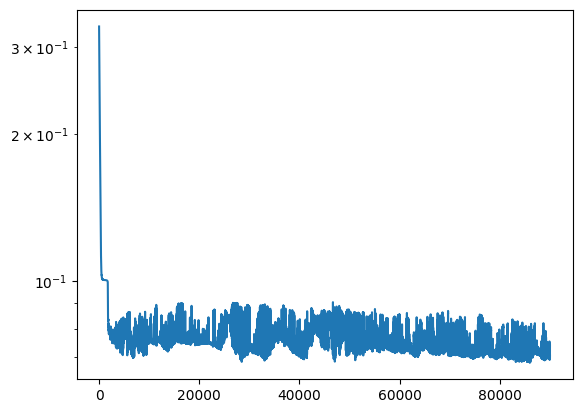

In [472]:


def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    

def physics_loss(model: torch.nn.Module):
    global PHYSICAL_LOSS_SCALING_FACTOR

    # Create time input for PINN
    ts = torch.linspace(0, 3600, steps=100, dtype=torch.float32).view(-1, 1).to(DEVICE).requires_grad_(True)
    ts_scaled = scaler_X.transform(ts)

    # Predict radius
    out = model(ts_scaled)
    d, Ea_net, A_net = out[:, 0], out[:, 1], out[:, 2]  # [-1, 1] [0, 1]
    d = scaler_Y.inverse_transform(d)
    
    #Ea = torch.nn.functional.softplus(Ea_net) * 1e5
    #A = torch.nn.functional.softplus(A_net) * 1e-3
    # Ea = Ea_net * 1e5 
    # A = A_net * 1e-3

    Ea = Ea_net
    A = A_net

    # Compute model's derivative wrt time
    dd = torch.autograd.grad(
        d, ts, 
        grad_outputs=torch.ones_like(d), 
        create_graph=True
    )[0]

    # Compute K
    K = A * torch.exp(-Ea / (R * T))
    # Theoretical Avrami derivative
    derived_eq = r_max * K * n * ts.pow(n - 1) * torch.exp(-K * ts.pow(n))

    pde_residual = dd - derived_eq
    # pde_residual = pde_residual * 1e12

    physical_loss = torch.mean(pde_residual**2)

    if PHYSICAL_LOSS_SCALING_FACTOR is None:
        # Get the maximum residual value as a float
        val = torch.max(physical_loss).item()
        # Compute the order-of-magnitude exponent. For a value like 5.23e-6,
        # math.log10(val) ≈ -5.28, and floor(-5.28) gives -6.
        exponent = -math.floor(math.log10(val))
        # Set the scaling factor as 10 raised to the computed exponent.
        # PHYSICAL_LOSS_SCALING_FACTOR = 10 ** exponent
        PHYSICAL_LOSS_SCALING_FACTOR = 1/abs(exponent)
        # PHYSICAL_LOSS_SCALING_FACTOR = 1e10
    # pde_residual = torch.pow(pde_residual, PHYSICAL_LOSS_SCALING_FACTOR)
    physical_loss = torch.pow(physical_loss, PHYSICAL_LOSS_SCALING_FACTOR)

    return physical_loss

# PHYSICAL_LOSS_SCALING_FACTOR = 1e-12
PHYSICAL_LOSS_SCALING_FACTOR = None

set_seed(0)
scaler_X = scaler_X.to(DEVICE)
scaler_Y = scaler_Y.to(DEVICE)
curr_train_times_X = train_times_X_scaled.to(DEVICE)
curr_train_d_Y = train_d_Y_scaled.to(DEVICE)


# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=150000, lr=1e-4).to(DEVICE)
net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=90000, lr=1e-4).to(DEVICE)
losses = net.fit(curr_train_times_X, curr_train_d_Y, scaler_Y)

plt.plot(losses)
plt.yscale('log')

Predicted A: 0.0245, Guess A: 0.005  -  abs difference: 0.02
Predicted Ea: 46416.05, Guess Ea: 60000  -  abs difference: 13583.95


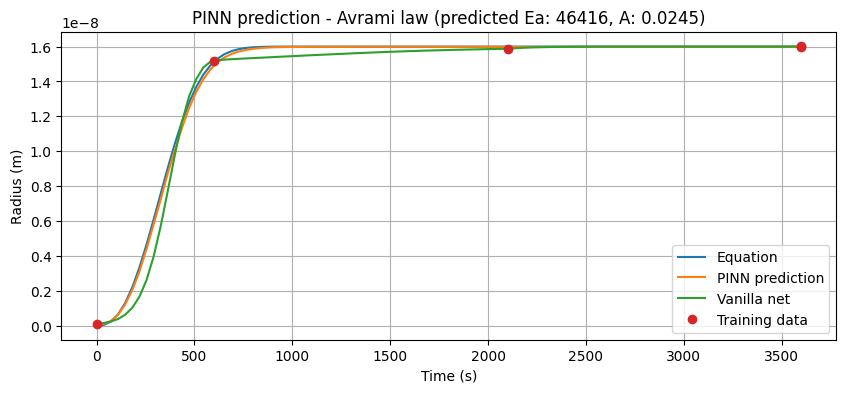

In [482]:
# plot the prediction on gt data

pred = net.predict(eq_times_X_scaled)
pred = torch.tensor(pred, dtype=torch.float32, device=DEVICE)
d, Ea_net, A_net = pred[:, 0], pred[:, 1], pred[:, 2]
d = scaler_Y.inverse_transform(d)
d = d.cpu().numpy()
Ea_net = Ea_net.cpu()
A_net = A_net.cpu()

# expected:
A_expected = 5e-3              # Increased to speed up transformation
Ea_expected = 60000           # Lowered to increase reaction rate

Ea = Ea_net  # torch.nn.functional.softplus(Ea_net) * 1e5
A = A_net  # torch.nn.functional.softplus(A_net) * 1e-3

print(f"Predicted A: {A.mean().item():.4f}, Guess A: {A_expected}  -  abs difference: {abs(A.mean().item() - A_expected):.2f}")
print(f"Predicted Ea: {Ea.mean().item():.2f}, Guess Ea: {Ea_expected}  -  abs difference: {abs(Ea.mean().item() - Ea_expected):.2f}")

vanilla_pred = vanilla.predict(eq_times_X_scaled)
vanilla_pred = torch.tensor(vanilla_pred, dtype=torch.float32, device=DEVICE)
vanilla_d = vanilla_pred[:, 0]
vanilla_d = scaler_Y.inverse_transform(vanilla_d)
vanilla_d = vanilla_d.cpu().numpy()
plt.figure(figsize=(10, 4))
# plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(gt_times_X, d, label="PINN prediction")
plt.plot(gt_times_X, vanilla_d, label="Vanilla net")
# plot train data
plt.plot(train_times_X, train_d_Y , 'o', label="Training data")
plt.title(f"PINN prediction - Avrami law (predicted Ea: {Ea.mean().item():.0f}, A: {A.mean().item():.4f})")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.grid()
plt.legend()
plt.show()